In [5]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


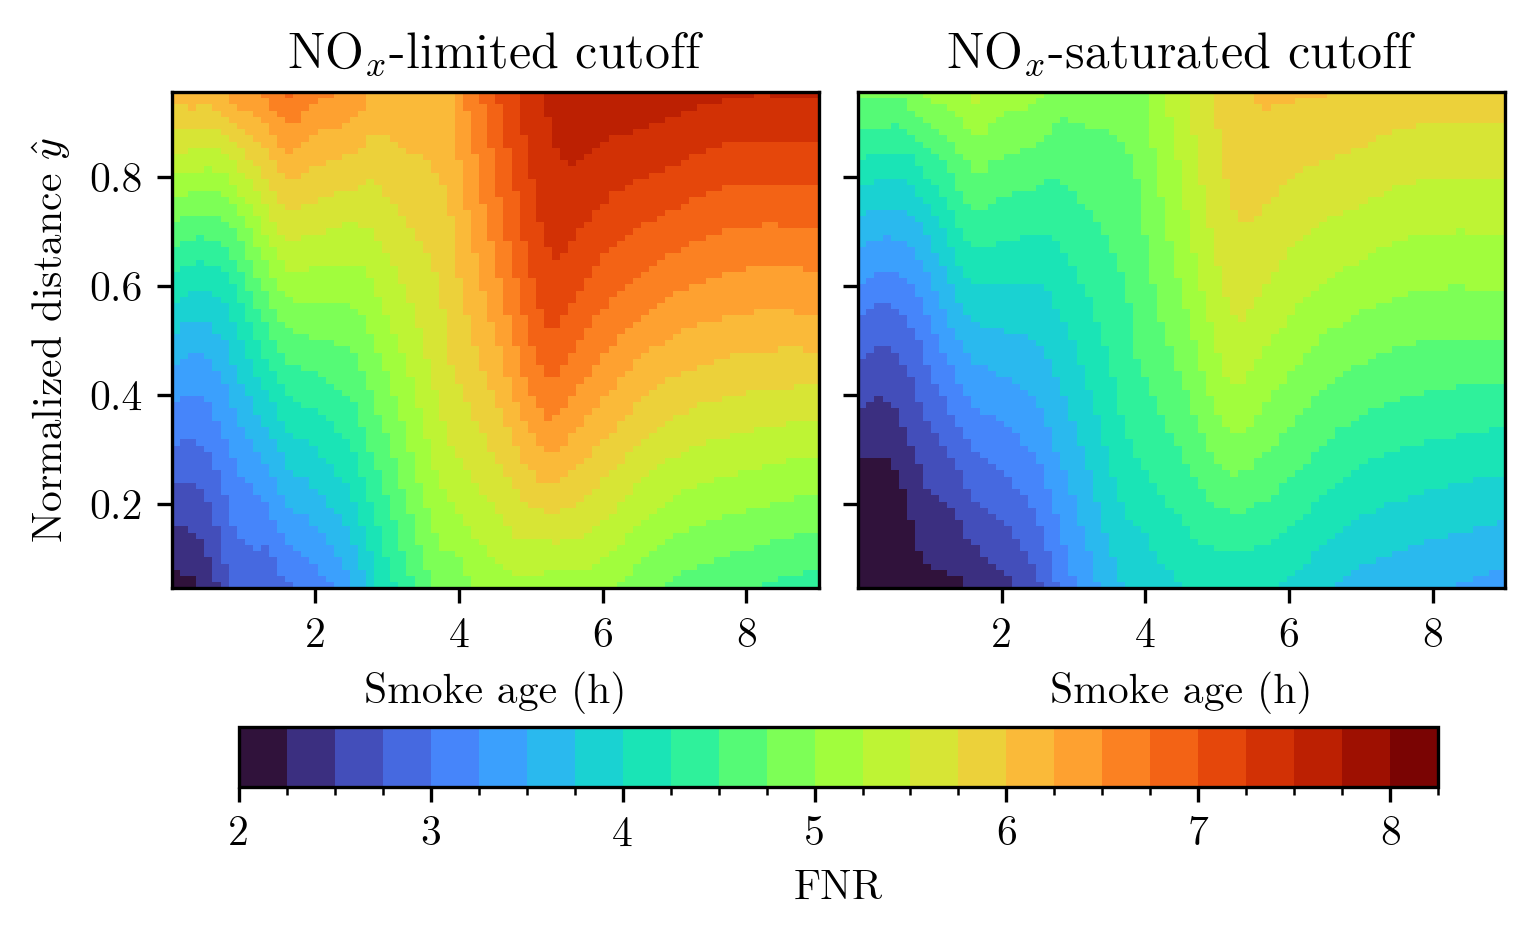

In [7]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm
from scipy.ndimage import gaussian_filter

CODE = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/code/airborne")
DATA = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data")
sys.path.insert(0, str(CODE))
from fnr_threshold import make_smooth_interpolant

age_edges = np.linspace(0, np.sqrt(10), 10) ** 2
y_edges = np.arange(0, 1.1, 0.1)
age_centers = 0.5 * (age_edges[:-1] + age_edges[1:])
y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
lim = np.load(DATA / "fnr_noxlim_thresholds.npz")["grid"]
sat = np.load(DATA / "fnr_noxsat_thresholds.npz")["grid"]
lim_of = make_smooth_interpolant(age_centers, y_centers, lim, smoothing=1, neighbors=20)
sat_of = make_smooth_interpolant(age_centers, y_centers, sat, smoothing=1, neighbors=20)

age_hi = np.linspace(age_centers.min(), age_centers.max(), 80)
y_hi = np.linspace(y_centers.min(), y_centers.max(), 80)
AA, YY = np.meshgrid(age_hi, y_hi, indexing="ij")
lim_hi = gaussian_filter(lim_of(AA, YY), sigma=0.7)
sat_hi = gaussian_filter(sat_of(AA, YY), sigma=0.7)

levels = np.arange(2, 8.5, 0.25)
norm = BoundaryNorm(levels, ncolors=plt.cm.turbo.N, clip=True)
fig, axes = plt.subplots(1, 2, figsize=(5, 3), dpi=300, sharey=True, layout="constrained")
for ax, field, title in (
    (axes[0], lim_hi, r"NO$_x$-limited cutoff"),
    (axes[1], sat_hi, r"NO$_x$-saturated cutoff"),
):
    mesh = ax.pcolormesh(age_hi, y_hi, field.T, shading="auto", cmap="turbo", norm=norm)
    ax.set_xlabel("Smoke age (h)")
    ax.set_title(title)
axes[0].set_ylabel(r"Normalized distance $\hat{y}$")
bar = fig.colorbar(mesh, ax=axes, orientation="horizontal", shrink=0.9, pad=0.02, ticks=np.arange(0, 11, 1))
bar.set_label("FNR")
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs07.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs07.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
